## PROJECT (Code Snippets)

In [1]:
!pip install nltk beautifulsoup4 pandas matplotlib scikit-learn spacy gensim seaborn
!python -m spacy download en_core_web_sm

     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     - -------------------------------------- 0.5/12.8 MB 4.2 MB/s eta 0:00:03
     --- ------------------------------------ 1.0/12.8 MB 4.6 MB/s eta 0:00:03
     ------- -------------------------------- 2.4/12.8 MB 4.2 MB/s eta 0:00:03
     ------------- -------------------------- 4.2/12.8 MB 5.6 MB/s eta 0:00:02
     -------------------- ------------------- 6.6/12.8 MB 6.8 MB/s eta 0:00:01
     ------------------------ --------------- 7.9/12.8 MB 7.3 MB/s eta 0:00:01
     --------------------------- ------------ 8.7/12.8 MB 6.5 MB/s eta 0:00:01
     --------------------------------- ------ 10.7/12.8 MB 6.8 MB/s eta 0:00:01
     ---------------------------------------  12.6/12.8 MB 7.2 MB/s eta 0:00:01
     ---------------------------------------- 12.8/12.8 MB 7.1 MB/s eta 0:00:00
[+] Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\abish\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\abish\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\abish\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


Accessing URL: https://finviz.com/quote.ashx?t=AMZN
Accessing URL: https://finviz.com/quote.ashx?t=GOOG
Accessing URL: https://finviz.com/quote.ashx?t=META
DataFrame Head:
  ticker       date     time                                                                            title  compound
0   AMZN 2025-03-17  09:39PM                       Inside Amazon's plan to reshape its Alexa devices business    0.0000
1   AMZN 2025-03-18  07:33PM           Is Amazon.com, Inc. (AMZN) the Best Strong Buy Stock to Buy Right Now?    0.8176
2   AMZN 2025-03-18  06:30PM                 2 No-Brainer Artificial Intelligence (AI) Stocks to Buy in March    0.4767
3   AMZN 2025-03-18  05:45PM          Amazon (AMZN) Stock Drops Despite Market Gains: Important Facts to Note   -0.2330
4   AMZN 2025-03-18  02:07PM  GDIT Partners with Amazon (AMZN) AWS to Drive Government Digital Transformation    0.1779

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
Index: 299 entries, 0 to 299
Data columns (total 5 co

<Figure size 800x200 with 0 Axes>

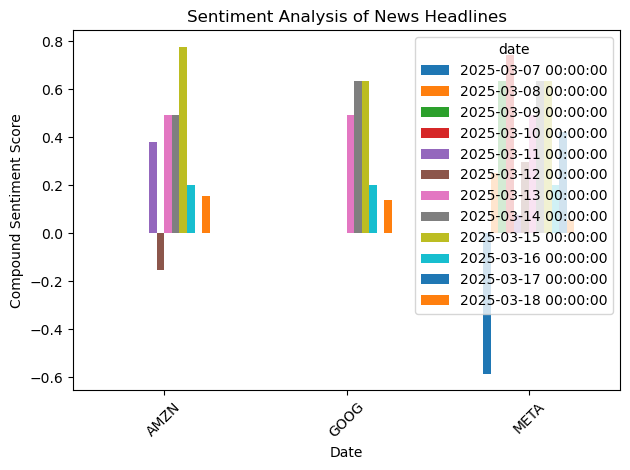

In [2]:
import nltk
nltk.download('vader_lexicon')

# For tokenization
nltk.download('punkt')  

# For POS tagging
nltk.download('averaged_perceptron_tagger')  
from urllib.request import urlopen, Request
from bs4 import BeautifulSoup
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

# For TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer 

# For stemming
from nltk.stem import PorterStemmer

# For lemmatization and NER
import spacy  

# For Word2Vec
from gensim.models import Word2Vec  

# For clustering
from sklearn.cluster import KMeans  

# For topic modeling
from sklearn.decomposition import LatentDirichletAllocation 

# For advanced visualizations
import seaborn as sns  

# Load spaCy model for lemmatization and NER
nlp = spacy.load('en_core_web_sm')

# Define the Finviz URL and tickers
finviz_url = 'https://finviz.com/quote.ashx?t='
tickers = ['AMZN', 'GOOG', 'META']  # Updated tickers

# Dictionary to store news tables for each ticker
news_tables = {}

# Fetch news data for each ticker
for ticker in tickers:
    url = finviz_url + ticker
    print(f"Accessing URL: {url}")  # Debugging: Print the URL

    # Send a request to the URL with a user-agent header
    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36'
    }
    req = Request(url=url, headers=headers)
    try:
        response = urlopen(req)
    except Exception as e:
        print(f"Error accessing {url}: {e}")
        continue

    # Parse the HTML content
    html = BeautifulSoup(response, features='html.parser')
    news_table = html.find(id='news-table')
    if news_table is None:
        print(f"No news table found for {ticker}. Skipping...")
        continue
    news_tables[ticker] = news_table

# Parse the news data
parsed_data = []

# Iterate over the news_tables dictionary
for ticker, news_table in news_tables.items():
    for row in news_table.findAll('tr'):
        # Extract the title
        title = row.a.text if row.a else None
        if not title:
            continue  # Skip rows without a title

        # Extract the date and time
        date_data = row.td.text.strip().split(' ')
        if len(date_data) == 1:
            time = date_data[0]
            date = datetime.now().date()  # Use current date if no date is available
        else:
            date = date_data[0]
            time = date_data[1]

        parsed_data.append([ticker, date, time, title])

# Create a DataFrame from the parsed data
df = pd.DataFrame(parsed_data, columns=['ticker', 'date', 'time', 'title'])

# Perform sentiment analysis using VADER
vader = SentimentIntensityAnalyzer()

# Apply sentiment analysis to each news title
df['compound'] = df['title'].apply(lambda title: vader.polarity_scores(title)['compound'])

# Convert the 'date' column to datetime format and extract the date part
df['date'] = pd.to_datetime(df['date'], format='%b-%d-%y', errors='coerce')  # Coerce invalid dates to NaT
df = df.dropna(subset=['date'])  # Drop rows with invalid dates

# Ensure the 'compound' column is numeric
df['compound'] = pd.to_numeric(df['compound'], errors='coerce')

# Debugging: Print the DataFrame and column types
print("DataFrame Head:")
print(df.head().to_string())
print("\nDataFrame Info:")
print(df.info())
print("\nDataFrame Description:")
print(df.describe())

# Group by ticker and date, then calculate the mean compound score
mean_df = df.groupby(['ticker', 'date'])['compound'].mean().unstack()

# Debugging: Print the grouped DataFrame
print("\nGrouped DataFrame:")
print(mean_df)

# Check if the grouped DataFrame is empty or contains no numeric data
if mean_df.empty or mean_df.isnull().all().all():
    print("No numeric data to plot. Check the input data.")
else:
    # Plot the results as a bar chart
    plt.figure(figsize=(8, 2))
    mean_df.plot(kind='bar')
    plt.title('Sentiment Analysis of News Headlines')
    plt.xlabel('Date')
    plt.ylabel('Compound Sentiment Score')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# --------------------------
# Additional Techniques
# --------------------------

In [3]:
# 1. TF-IDF Calculation
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(df['title'])
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf.get_feature_names_out())
print("\nTF-IDF DataFrame:")
print(tfidf_df.head())



TF-IDF DataFrame:
   000   10  16e   19  19th  2025  2025watch  2028  2035  2050  ...  worked  \
0  0.0  0.0  0.0  0.0   0.0   0.0        0.0   0.0   0.0   0.0  ...     0.0   
1  0.0  0.0  0.0  0.0   0.0   0.0        0.0   0.0   0.0   0.0  ...     0.0   
2  0.0  0.0  0.0  0.0   0.0   0.0        0.0   0.0   0.0   0.0  ...     0.0   
3  0.0  0.0  0.0  0.0   0.0   0.0        0.0   0.0   0.0   0.0  ...     0.0   
4  0.0  0.0  0.0  0.0   0.0   0.0        0.0   0.0   0.0   0.0  ...     0.0   

   works  worth  wrote  wsj  year  years  yield  youtubers  zuckerberg  
0    0.0    0.0    0.0  0.0   0.0    0.0    0.0        0.0         0.0  
1    0.0    0.0    0.0  0.0   0.0    0.0    0.0        0.0         0.0  
2    0.0    0.0    0.0  0.0   0.0    0.0    0.0        0.0         0.0  
3    0.0    0.0    0.0  0.0   0.0    0.0    0.0        0.0         0.0  
4    0.0    0.0    0.0  0.0   0.0    0.0    0.0        0.0         0.0  

[5 rows x 918 columns]


In [4]:
# 2. Stemming
stemmer = PorterStemmer()
df['stemmed_title'] = df['title'].apply(lambda x: ' '.join([stemmer.stem(word) for word in x.split()]))
print("\nStemmed Titles:")
print(df[['title', 'stemmed_title']].head())



Stemmed Titles:
                                               title  \
0  Inside Amazon's plan to reshape its Alexa devi...   
1  Is Amazon.com, Inc. (AMZN) the Best Strong Buy...   
2  2 No-Brainer Artificial Intelligence (AI) Stoc...   
3  Amazon (AMZN) Stock Drops Despite Market Gains...   
4  GDIT Partners with Amazon (AMZN) AWS to Drive ...   

                                       stemmed_title  
0   insid amazon' plan to reshap it alexa devic busi  
1  is amazon.com, inc. (amzn) the best strong buy...  
2  2 no-brain artifici intellig (ai) stock to buy...  
3  amazon (amzn) stock drop despit market gains: ...  
4  gdit partner with amazon (amzn) aw to drive go...  


In [5]:
# 3. Lemmatization
df['lemmatized_title'] = df['title'].apply(lambda x: ' '.join([token.lemma_ for token in nlp(x)]))
print("\nLemmatized Titles:")
print(df[['title', 'lemmatized_title']].head())



Lemmatized Titles:
                                               title  \
0  Inside Amazon's plan to reshape its Alexa devi...   
1  Is Amazon.com, Inc. (AMZN) the Best Strong Buy...   
2  2 No-Brainer Artificial Intelligence (AI) Stoc...   
3  Amazon (AMZN) Stock Drops Despite Market Gains...   
4  GDIT Partners with Amazon (AMZN) AWS to Drive ...   

                                    lemmatized_title  
0  inside Amazon 's plan to reshape its Alexa dev...  
1  be Amazon.com , Inc. ( AMZN ) the Best Strong ...  
2  2 no - Brainer Artificial Intelligence ( AI ) ...  
3  Amazon ( AMZN ) Stock Drops despite Market gai...  
4  GDIT Partners with Amazon ( AMZN ) aw to drive...  


In [6]:
# 4. Word2Vec
sentences = [title.split() for title in df['title']]
word2vec_model = Word2Vec(sentences, vector_size=100, window=5, min_count=1, workers=4)
print("\nWord2Vec Vector for 'Amazon':")
print(word2vec_model.wv['Amazon'])


Word2Vec Vector for 'Amazon':
[-9.8306304e-03  1.0803406e-02 -7.8723002e-03 -2.4575605e-03
 -5.2503715e-03 -6.9937813e-03 -7.3312405e-03 -5.1984377e-03
 -5.7410579e-03 -1.8480825e-03 -5.3586317e-03  4.9112882e-03
 -9.7115831e-03 -5.0693927e-03  9.9469740e-03  6.2910574e-03
  8.0603100e-03  2.8916164e-03  3.2448853e-04 -8.9276088e-03
  7.3004640e-03  3.0947484e-03  8.8889152e-03  5.7417159e-03
  7.4905949e-03  8.5901292e-03 -1.0707177e-02 -7.6702605e-03
  7.9924217e-04  7.0675169e-03  9.1731297e-03  5.2228612e-03
  8.5476404e-03 -6.1057620e-03  6.4563621e-03 -2.5980992e-03
 -9.2283459e-03  8.1516691e-03  5.6257995e-04 -5.2042245e-03
 -2.3200144e-03 -5.3186347e-03  4.8626089e-03  5.0819027e-03
 -1.6221994e-03 -7.8179501e-03 -4.3490431e-03 -4.7989690e-04
  6.8600317e-03 -2.0669352e-03  1.4371253e-04 -2.8021578e-04
 -7.2149467e-03  2.1532369e-03 -2.1158813e-03  3.1852266e-03
  5.2644373e-03 -1.7605559e-03 -4.5110970e-03  8.0165425e-03
  5.7218769e-03  6.8996055e-03  4.3535284e-03  8.69620

In [7]:
# 5. Named Entity Recognition (NER)
df['entities'] = df['title'].apply(lambda x: [(ent.text, ent.label_) for ent in nlp(x).ents])
print("\nNamed Entities in Titles:")
print(df[['title', 'entities']].head())


Named Entities in Titles:
                                               title  \
0  Inside Amazon's plan to reshape its Alexa devi...   
1  Is Amazon.com, Inc. (AMZN) the Best Strong Buy...   
2  2 No-Brainer Artificial Intelligence (AI) Stoc...   
3  Amazon (AMZN) Stock Drops Despite Market Gains...   
4  GDIT Partners with Amazon (AMZN) AWS to Drive ...   

                                            entities  
0                      [(Amazon, ORG), (Alexa, ORG)]  
1                        [(Amazon.com, Inc. (, ORG)]  
2  [(2, CARDINAL), (No-Brainer Artificial Intelli...  
3                                    [(Amazon, ORG)]  
4  [(Amazon, ORG), (Drive Government Digital Tran...  


In [8]:
# 6. POS Tagging
df['pos_tags'] = df['title'].apply(lambda x: [(token.text, token.pos_) for token in nlp(x)])
print("\nPOS Tags in Titles:")
print(df[['title', 'pos_tags']].head())


POS Tags in Titles:
                                               title  \
0  Inside Amazon's plan to reshape its Alexa devi...   
1  Is Amazon.com, Inc. (AMZN) the Best Strong Buy...   
2  2 No-Brainer Artificial Intelligence (AI) Stoc...   
3  Amazon (AMZN) Stock Drops Despite Market Gains...   
4  GDIT Partners with Amazon (AMZN) AWS to Drive ...   

                                            pos_tags  
0  [(Inside, ADP), (Amazon, PROPN), ('s, PART), (...  
1  [(Is, AUX), (Amazon.com, PROPN), (,, PUNCT), (...  
2  [(2, NUM), (No, NOUN), (-, PUNCT), (Brainer, P...  
3  [(Amazon, PROPN), ((, PUNCT), (AMZN, PROPN), (...  
4  [(GDIT, PROPN), (Partners, PROPN), (with, ADP)...  


In [9]:
# 7. Clustering (KMeans on TF-IDF)
num_clusters = 3
kmeans = KMeans(n_clusters=num_clusters, random_state=42)
df['cluster'] = kmeans.fit_predict(tfidf_matrix)
print("\nClustered Titles:")
print(df[['title', 'cluster']].head())

C:\Users\abish\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\abish\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\abish\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\abish\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\abish\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro


Clustered Titles:
                                               title  cluster
0  Inside Amazon's plan to reshape its Alexa devi...        1
1  Is Amazon.com, Inc. (AMZN) the Best Strong Buy...        2
2  2 No-Brainer Artificial Intelligence (AI) Stoc...        2
3  Amazon (AMZN) Stock Drops Despite Market Gains...        1
4  GDIT Partners with Amazon (AMZN) AWS to Drive ...        1


In [10]:
# 8. Topic Modeling (LDA)
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda.fit(tfidf_matrix)
print("\nTopics from LDA:")
for idx, topic in enumerate(lda.components_):
    print(f"Topic {idx}:")
    print([tfidf.get_feature_names_out()[i] for i in topic.argsort()[-10:]])


Topics from LDA:
Topic 0:
['decade', 'portfolio', 'sell', 'picks', 'hold', 'stocks', 'tech', 'amazon', 'ai', 'meta']
Topic 1:
['sign', 'ai', 'energy', 'today', 'boost', 'stock', 'google', 'amazon', 'nuclear', 'meta']
Topic 2:
['amazon', 'google', 'googl', 'nvidia', 'buy', 'meta', 'invest', 'best', 'alphabet', 'stock']
Topic 3:
['stock', 'jim', 'mag', 'cramer', 'amazon', 'stocks', 'buy', 'crushed', 'gotten', 'meta']
Topic 4:
['seven', 'magnificent', 'buying', 'artificial', 'intelligence', 'ai', 'buy', 'nasdaq', 'correction', 'stocks']


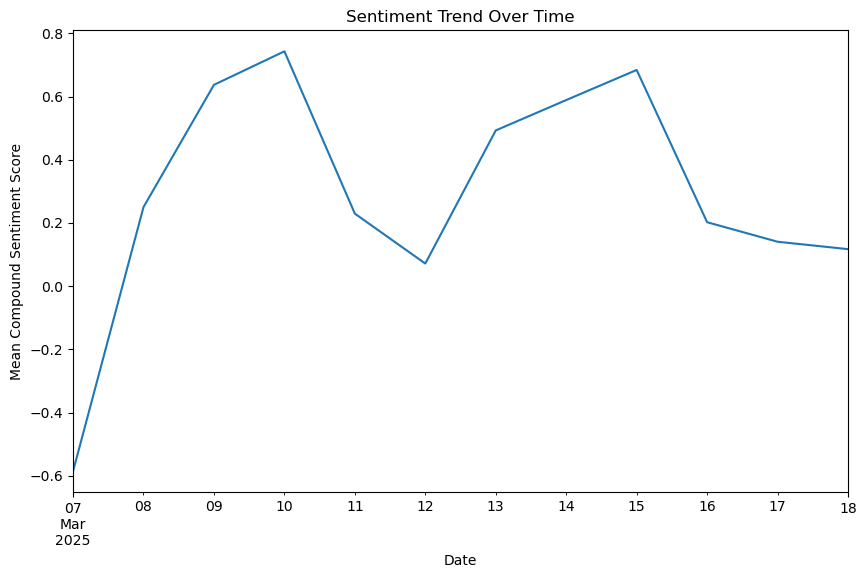

In [11]:
# 9. Sentiment Trend Analysis
df['date'] = pd.to_datetime(df['date'])
sentiment_trend = df.groupby('date')['compound'].mean()
plt.figure(figsize=(10, 6))
sentiment_trend.plot()
plt.title('Sentiment Trend Over Time')
plt.xlabel('Date')
plt.ylabel('Mean Compound Sentiment Score')
plt.show()

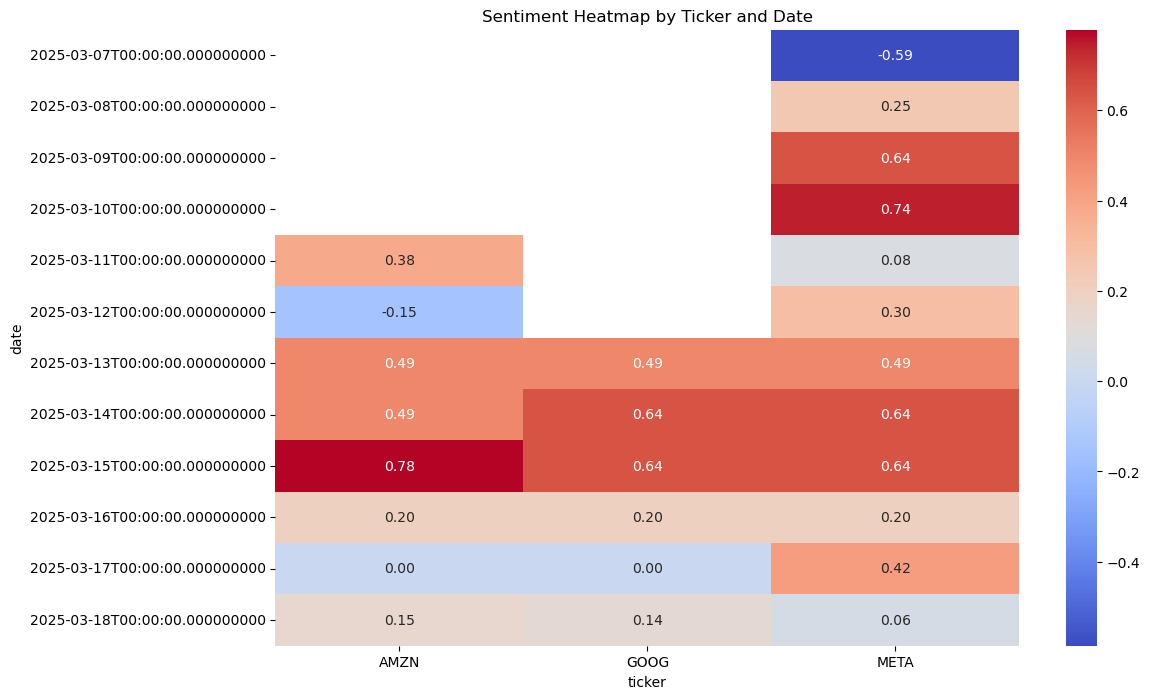

In [12]:
# 10. Advanced Visualization (Heatmap)
pivot_df = df.pivot_table(index='date', columns='ticker', values='compound', aggfunc='mean')
plt.figure(figsize=(12, 8))
sns.heatmap(pivot_df, cmap='coolwarm', annot=True, fmt=".2f")
plt.title('Sentiment Heatmap by Ticker and Date')
plt.show()

In [13]:
# Scrape news headlines
for ticker in tickers:
    url = finviz_url + ticker
    req = Request(url=url, headers=headers)
    response = urlopen(req)
    html = BeautifulSoup(response, features='html.parser')
    news_table = html.find(id='news-table')
    news_tables[ticker] = news_table


In [17]:
# Parse news data
parsed_data = []
for ticker, news_table in news_tables.items():
    for row in news_table.findAll('tr'):
        title = row.a.text if row.a else None
        date_data = row.td.text.strip().split(' ')
        if len(date_data) == 1:
            time = date_data[0]
            date = datetime.now().date()
        else:
            date = date_data[0]
            time = date_data[1]
        parsed_data.append([ticker, date, time, title])

# Create DataFrame
df = pd.DataFrame(parsed_data, columns=['ticker', 'date', 'time', 'title'])
print(df)

    ticker        date     time  \
0     AMZN   Mar-17-25  09:39PM   
1     AMZN  2025-03-18  07:33PM   
2     AMZN  2025-03-18  06:30PM   
3     AMZN  2025-03-18  05:45PM   
4     AMZN  2025-03-18  02:07PM   
..     ...         ...      ...   
295   META   Mar-07-25  07:03PM   
296   META  2025-03-18  05:45PM   
297   META  2025-03-18  11:52AM   
298   META  2025-03-18  10:00AM   
299   META  2025-03-18  09:58AM   

                                                 title  
0    Inside Amazon's plan to reshape its Alexa devi...  
1    Is Amazon.com, Inc. (AMZN) the Best Strong Buy...  
2    2 No-Brainer Artificial Intelligence (AI) Stoc...  
3    Amazon (AMZN) Stock Drops Despite Market Gains...  
4    GDIT Partners with Amazon (AMZN) AWS to Drive ...  
..                                                 ...  
295  Meta uses sneaky tactic to block ex-employees ...  
296  Meta Platforms (META) Stock Declines While Mar...  
297  Meta Platforms, Inc. (META): Jim Cramer on Met...  
298  From

Model-1: Sentiment Analysis with VADER

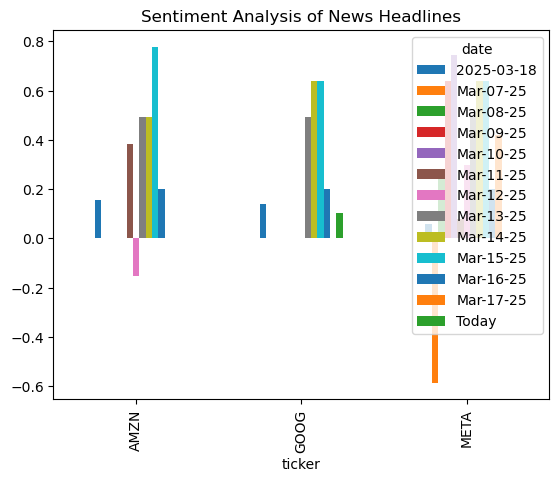

In [15]:
# Perform sentiment analysis
vader = SentimentIntensityAnalyzer()
df['compound'] = df['title'].apply(lambda title: vader.polarity_scores(title)['compound'])

# Group by ticker and date
mean_df = df.groupby(['ticker', 'date'])['compound'].mean().unstack()

# Plot sentiment analysis
mean_df.plot(kind='bar')
plt.title('Sentiment Analysis of News Headlines')
plt.show()


Model-2: Topic Modeling with LDA


In [16]:
# Perform LDA on TF-IDF vectors
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda.fit(tfidf_matrix)

# Display topics
for idx, topic in enumerate(lda.components_):
    print(f"Topic {idx}:")
    print([tfidf.get_feature_names_out()[i] for i in topic.argsort()[-10:]])
    

Topic 0:
['decade', 'portfolio', 'sell', 'picks', 'hold', 'stocks', 'tech', 'amazon', 'ai', 'meta']
Topic 1:
['sign', 'ai', 'energy', 'today', 'boost', 'stock', 'google', 'amazon', 'nuclear', 'meta']
Topic 2:
['amazon', 'google', 'googl', 'nvidia', 'buy', 'meta', 'invest', 'best', 'alphabet', 'stock']
Topic 3:
['stock', 'jim', 'mag', 'cramer', 'amazon', 'stocks', 'buy', 'crushed', 'gotten', 'meta']
Topic 4:
['seven', 'magnificent', 'buying', 'artificial', 'intelligence', 'ai', 'buy', 'nasdaq', 'correction', 'stocks']


Training, Analysis

In [21]:
# Check for empty or invalid titles
print("Number of rows before filtering:", len(df))
df = df[df['title'].notna() & (df['title'] != '')]  # Remove empty or NaN titles
print("Number of rows after filtering:", len(df))

# Recreate TF-IDF matrix with filtered data
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(df['title'])

# Perform clustering
kmeans = KMeans(n_clusters=3, random_state=42)
df['cluster'] = kmeans.fit_predict(tfidf_matrix)

# Print the updated DataFrame
print(df)

Number of rows before filtering: 300
Number of rows after filtering: 300
    ticker        date     time  \
0     AMZN   Mar-17-25  09:39PM   
1     AMZN  2025-03-18  07:33PM   
2     AMZN  2025-03-18  06:30PM   
3     AMZN  2025-03-18  05:45PM   
4     AMZN  2025-03-18  02:07PM   
..     ...         ...      ...   
295   META   Mar-07-25  07:03PM   
296   META  2025-03-18  05:45PM   
297   META  2025-03-18  11:52AM   
298   META  2025-03-18  10:00AM   
299   META  2025-03-18  09:58AM   

                                                 title  cluster  
0    Inside Amazon's plan to reshape its Alexa devi...        1  
1    Is Amazon.com, Inc. (AMZN) the Best Strong Buy...        2  
2    2 No-Brainer Artificial Intelligence (AI) Stoc...        2  
3    Amazon (AMZN) Stock Drops Despite Market Gains...        1  
4    GDIT Partners with Amazon (AMZN) AWS to Drive ...        1  
..                                                 ...      ...  
295  Meta uses sneaky tactic to block ex-emp